# ЛР 8. Линейная регрессия

Предсказываем месячную цену аренды квартиры в Астане и смотрим, что сильнее всего влияет на цену. Данные лежат в `data/astana_rent_clean.csv`. Это 600 объявлений после очистки в ЛР 7.

В выданном файле нет столбца `dist_center` с расстоянием до центра. В шаге 6 вместо него берём год постройки `year`, а в шаге 7 площадь `area`.

Служебные столбцы из ЛР 7 в модель не берём. Это `area_raw`, `area_nan`, `price_m2`, `floor_type` и `age_group`. Столбец `price_m2` равен `price / area`, то есть в нём уже есть ответ.

## Шаг 2. Загрузка и разбиение на обучение и тест

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=UserWarning)  # KBinsDiscretizer предупреждает о пустых интервалах
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/astana_rent_clean.csv")
print(df.shape)
df = df[["id", "date", "district", "rooms", "area", "floor", "floors", "year", "furniture", "price"]]
print(df.shape)
print(df.isna().sum()[lambda s: s > 0].to_dict())

train, test = train_test_split(df, test_size=0.25, random_state=42)
print(train.shape, test.shape)

(600, 15)
(600, 10)
{'floor': 2, 'year': 27, 'furniture': 45}
(450, 10) (150, 10)


Тест, 150 объявлений, откладываем сразу и не смотрим на него при выборе модели. Медианы, категории и α считаем только по `train`. `random_state=42` делает разбиение одинаковым при каждом запуске.

## Шаг 3. Парная регрессия по формуле

In [2]:
from sklearn.linear_model import LinearRegression

tr = train.dropna(subset=["area"])
X = np.column_stack([np.ones(len(tr)), tr["area"]])  # столбец единиц даёт сдвиг w0
y = tr["price"].to_numpy()

w = np.linalg.solve(X.T @ X, X.T @ y)  # решаем (XᵀX) w = Xᵀy
print(w.round(1))

lr = LinearRegression().fit(tr[["area"]], y)
print(round(lr.intercept_, 1), lr.coef_.round(1))

[9122.1 4265.1]
9122.1 [4265.1]


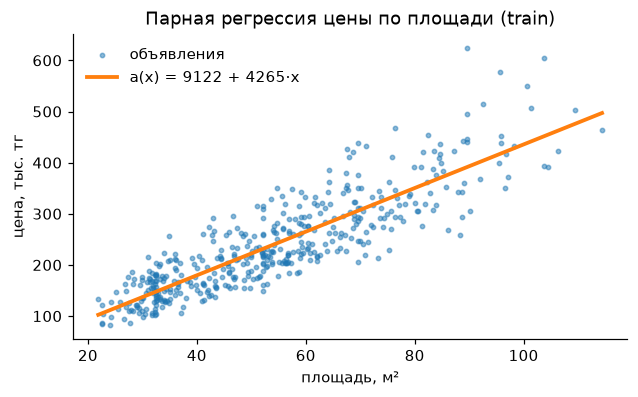

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.scatter(tr["area"], tr["price"] / 1000, s=8, alpha=.5, label="объявления")
xx = np.linspace(tr["area"].min(), tr["area"].max(), 100)
ax.plot(xx, (w[0] + w[1] * xx) / 1000, color="tab:orange", lw=2.5,
        label=f"a(x) = {w[0]:.0f} + {w[1]:.0f}·x")
ax.set_xlabel("площадь, м²")
ax.set_ylabel("цена, тыс. тг")
ax.legend(frameon=False)
ax.set_title("Парная регрессия цены по площади (train)")
plt.show()

**Вывод.** Формула и `LinearRegression` дали одинаковые веса, цена ≈ 9 122 + 4 265 · площадь. Каждый квадратный метр добавляет к цене около 4 265 тг в месяц. Сдвиг 9 122 сам по себе ничего не значит, квартир площадью 0 м² не бывает.

## Шаг 4. MSE в векторной форме

In [4]:
from sklearn.metrics import mean_squared_error, r2_score

mse = np.square(X @ w - y).mean()  # MSE без цикла
print(round(mse), round(np.sqrt(mse)))

te = test.dropna(subset=["area"])
pred = lr.predict(te[["area"]])
print("test RMSE", round(np.sqrt(mean_squared_error(te["price"], pred))),
      "R2", round(r2_score(te["price"], pred), 3))

2213187001 47045
test RMSE 47198 R2 0.756


**Вывод.** MSE ≈ 2,2 млрд. Это квадрат тенге, поэтому удобнее смотреть на RMSE. На обучении она 47 045 тг, на тесте 47 198 тг, R² = 0,756.

Одна площадь объясняет примерно три четверти разброса цен. Ошибки на обучении и тесте почти равны. Значит, модель не переобучилась, она слишком простая. Нужны другие признаки.

## Шаг 5. Множественная регрессия в Pipeline

In [5]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = ["rooms", "area", "floor", "floors", "year"]
cat_cols = ["district", "furniture"]
X_train, y_train = train[num_cols + cat_cols], train["price"]
X_test,  y_test  = test[num_cols + cat_cols],  test["price"]

def make_prep(num=num_cols):
    return make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
        (make_pipeline(SimpleImputer(strategy="most_frequent"),
                       OneHotEncoder(handle_unknown="ignore")), cat_cols))

model = make_pipeline(make_prep(), LinearRegression())
scores = cross_val_score(model, X_train, y_train, cv=5, scoring="r2")
print(scores.round(3), scores.mean().round(3))
model.fit(X_train, y_train)
print("test R2", round(model.score(X_test, y_test), 3))

names = [n.split("__")[1] for n in model[:-1].get_feature_names_out()]
coefs = pd.Series(model[-1].coef_, index=names)
print(coefs.round(0).sort_values())

[0.931 0.904 0.89  0.924 0.933] 0.916
test R2 0.914
district_Алматы     -32274.0
district_Байконур   -23170.0
district_Сарыарка   -13846.0
furniture_no         -5736.0
floor                -1128.0
rooms                 1215.0
floors                1287.0
furniture_yes         5736.0
district_Нура        11697.0
year                 14562.0
district_Есиль       57594.0
area                 85605.0
dtype: float64


**Вывод.**
- R² на кросс-валидации вырос с 0,756 до 0,916. По фолдам он от 0,89 до 0,93, на тесте 0,914.
- Числовые признаки стандартизированы. Поэтому вес показывает, на сколько меняется цена, если признак вырос на одно стандартное отклонение. Сильнее всего влияет площадь, +85 605. У года постройки +14 562, новые дома дороже.
- Веса районов сравниваем между собой. Есиль (+57 594) дороже Алматинского района (−32 274) примерно на 90 тыс. тг при прочих равных.
- У `furniture_no` вес −5 736, у `furniture_yes` +5 736. Так получается из-за one-hot. Столбцы одной группы в сумме всегда дают 1, поэтому они зависят друг от друга. Подробнее в шаге 8. Квартира с мебелью дороже примерно на 11,5 тыс. тг.

## Шаг 6. Интервалы для года постройки

В методичке на интервалы режут `dist_center`. У нас его нет, поэтому пробуем то же на `year`. Смотрим, как цена квадратного метра зависит от года, и сравниваем прямую со средними по 8 интервалам.

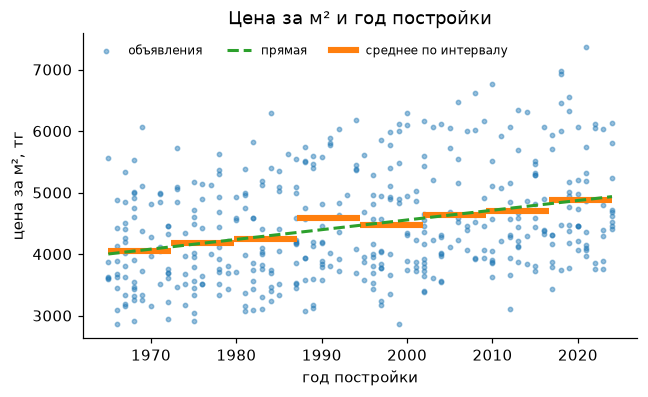

bin
(1964.999, 1972.375]    4053.0
(1972.375, 1979.75]     4174.0
(1979.75, 1987.125]     4245.0
(1987.125, 1994.5]      4581.0
(1994.5, 2001.875]      4472.0
(2001.875, 2009.25]     4640.0
(2009.25, 2016.625]     4696.0
(2016.625, 2024.0]      4887.0
Name: price_m2, dtype: float64


In [6]:
d = train.dropna(subset=["area", "year"]).copy()
d["price_m2"] = d["price"] / d["area"]
edges = np.linspace(d["year"].min(), d["year"].max(), 9)
d["bin"] = pd.cut(d["year"], edges, include_lowest=True)
means = d.groupby("bin", observed=True)["price_m2"].mean()

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.scatter(d["year"], d["price_m2"], s=8, alpha=.45, label="объявления")
for (iv, m) in means.items():
    ax.hlines(m, iv.left, iv.right, color="tab:orange", lw=4)
k, b = np.polyfit(d["year"], d["price_m2"], 1)
xx = np.array([d["year"].min(), d["year"].max()])
ax.plot(xx, k * xx + b, "--", color="tab:green", lw=2, label="прямая")
ax.plot([], [], color="tab:orange", lw=4, label="среднее по интервалу")
ax.set_xlabel("год постройки")
ax.set_ylabel("цена за м², тг")
ax.legend(frameon=False, ncol=3, fontsize=8)
ax.set_title("Цена за м² и год постройки")
plt.show()
print(means.round(0))

Средняя цена за м² ровно растёт от ~4 050 тг у домов 1965–1972 годов до ~4 890 тг у домов 2017–2024 годов. Ступеньки лежат почти на прямой, изгиба нет. Проверим, станет ли модель лучше с интервалами.

In [7]:
from sklearn.preprocessing import KBinsDiscretizer

num_wo = ["rooms", "area", "floor", "floors"]

def make_prep_bins(n_bins=8):
    return make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_wo),
        # KBinsDiscretizer не принимает пропуски, поэтому сначала медиана
        (make_pipeline(SimpleImputer(strategy="median"),
                       KBinsDiscretizer(n_bins=n_bins, encode="onehot", strategy="uniform")), ["year"]),
        (make_pipeline(SimpleImputer(strategy="most_frequent"),
                       OneHotEncoder(handle_unknown="ignore")), cat_cols))

model_b = make_pipeline(make_prep_bins(), LinearRegression())
scores = cross_val_score(model_b, X_train, y_train, cv=5, scoring="r2")
print(scores.round(3), scores.mean().round(3))
model_b.fit(X_train, y_train)
print("test", round(model_b.score(X_test, y_test), 3))

[0.928 0.903 0.887 0.923 0.931] 0.914
test 0.911


**Вывод.** С интервалами R² на кросс-валидации 0,914, без них 0,916. На тесте 0,911 против 0,914. Качество не выросло.

Цена и так растёт с годом почти по прямой, а вместо одного веса модель теперь учит восемь. Лишние веса только добавляют шум. Интервалы помогают, когда признак связан с целью не по прямой. Здесь связь прямая, поэтому они не нужны. В шаге 12 это проверяется ещё раз отдельным экспериментом.

## Шаг 7. Переобучение на малой выборке

Берём 30 объявлений и предсказываем цену квадратного метра полиномом степени 1, 4 и 15. В методичке признак `dist_center`, у нас площадь `area`.

Год здесь не подходит. Его значения около 2000, и `year¹⁵` получается таким огромным, что расчёт ломается ещё до регуляризации. Качество проверяем на тесте, это 150 объявлений.

In [8]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

small = train.dropna(subset=["area"]).sample(30, random_state=1).copy()
small["price_m2"] = small["price"] / small["area"]
big = test.dropna(subset=["area"]).copy()
big["price_m2"] = big["price"] / big["area"]
xs, ys = small[["area"]], small["price_m2"]
xb, yb = big[["area"]], big["price_m2"]

def rmse(m, X, y):
    return round(np.sqrt(mean_squared_error(y, m.predict(X))))

def poly(deg, reg):
    return make_pipeline(PolynomialFeatures(deg, include_bias=False), StandardScaler(), reg)

fits = {}
for deg in [1, 4, 15]:
    m = poly(deg, LinearRegression()).fit(xs, ys)
    fits[f"степень {deg}"] = m
    print(deg, "train RMSE", rmse(m, xs, ys), "test RMSE", rmse(m, xb, yb),
          "max|w|", f"{np.abs(m[-1].coef_).max():.3g}")

1 train RMSE 922 test RMSE 834 max|w| 61.9
4 train RMSE 877 test RMSE 897 max|w| 3.97e+04
15 train RMSE 762 test RMSE 38531 max|w| 5.28e+06


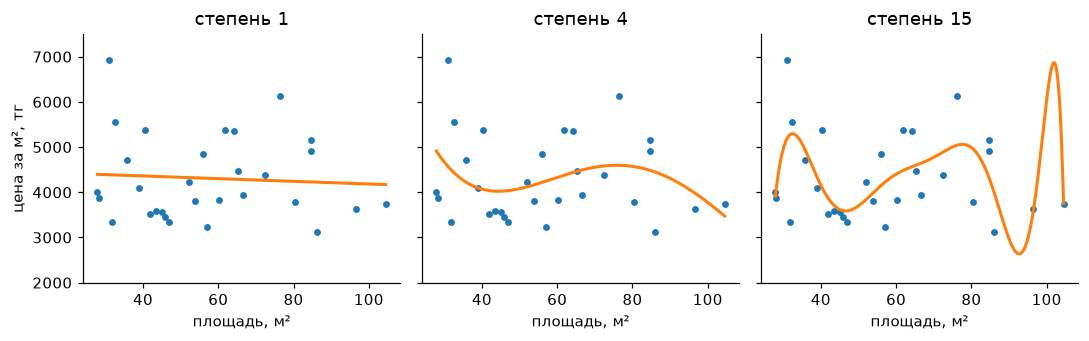

In [9]:
def plot_fits(fits):
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
    grid = pd.DataFrame({"area": np.linspace(xs["area"].min(), xs["area"].max(), 400)})
    for ax, (title, m) in zip(axes, fits.items()):
        ax.scatter(xs["area"], ys, s=12)
        ax.plot(grid["area"], m.predict(grid), color="tab:orange", lw=2)
        ax.set_title(title)
        ax.set_xlabel("площадь, м²")
        ax.set_ylim(2000, 7500)
    axes[0].set_ylabel("цена за м², тг")
    plt.tight_layout()
    plt.show()

plot_fits(fits)

Чем выше степень, тем меньше ошибка на обучении (922, 877, 762) и тем больше на тесте (834, 897, 38 531). У полинома степени 15 веса доходят до 5,3 млн. Так выглядит переобучение. Кривая проходит рядом со всеми 30 точками и сильно скачет между ними. Добавим L2-штраф с разными α.

ridge 0.01 train 857 test 1545 max|w| 2.59e+03
ridge 1 train 903 test 840 max|w| 235
ridge 100 train 915 test 836 max|w| 11.8


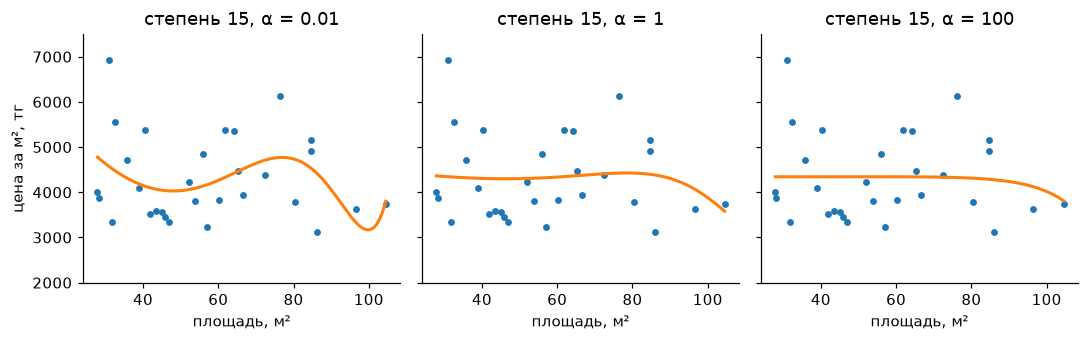

In [10]:
fits_r = {}
for a in [0.01, 1, 100]:
    m = poly(15, Ridge(alpha=a)).fit(xs, ys)
    fits_r[f"степень 15, α = {a}"] = m
    print("ridge", a, "train", rmse(m, xs, ys), "test", rmse(m, xb, yb),
          "max|w|", f"{np.abs(m[-1].coef_).max():.3g}")
plot_fits(fits_r)

**Вывод.** Со штрафом самый большой вес упал с 5,3 млн до 235 при α = 1 и до 11,8 при α = 100. Ошибка на тесте упала с 38 531 примерно до 840, как у обычной прямой.

При α = 0,01 штраф слишком слабый, на тесте 1 545. При α = 100 кривая уже почти прямая. Если увеличивать α дальше, модель станет константой и перестанет учиться. Поэтому α подбирают на кросс-валидации.

## Шаг 8. Ridge и Lasso с подбором α

In [11]:
from sklearn.linear_model import RidgeCV, LassoCV

regs = {
    "ridge": RidgeCV(alphas=np.logspace(-2, 3, 30)),
    "lasso": LassoCV(alphas=np.logspace(0, 4, 30), cv=5, random_state=42, max_iter=50000),
}
for name, reg in regs.items():
    m = make_pipeline(make_prep_bins(), reg)
    cv = cross_val_score(m, X_train, y_train, cv=5, scoring="r2").mean()
    m.fit(X_train, y_train)
    zeros = int((np.abs(m[-1].coef_) < 1e-6).sum())
    print(name, "alpha", round(m[-1].alpha_, 3), "cv", cv.round(3),
          "test", round(m.score(X_test, y_test), 3),
          "zeros", zeros, "of", len(m[-1].coef_))
lasso = m  # после цикла в m лежит Lasso

ridge alpha 0.788 cv 0.914 test 0.912 zeros 0 of 19


lasso alpha 62.102 cv 0.914 test 0.912 zeros 2 of 19


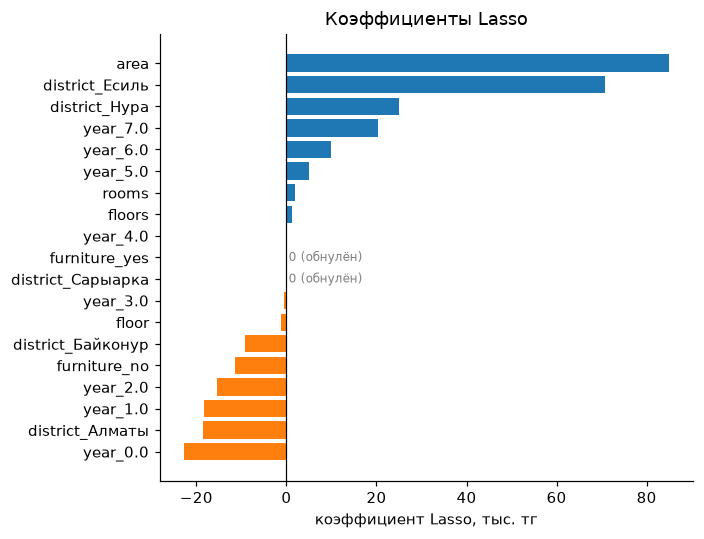

обнулены: ['district_Сарыарка', 'furniture_yes']
year_0.0   -22757.0
year_1.0   -18287.0
year_2.0   -15401.0
year_3.0     -577.0
year_4.0       10.0
year_5.0     5113.0
year_6.0     9943.0
year_7.0    20315.0
dtype: float64


In [12]:
lnames = [n.split("__")[1] for n in lasso[:-1].get_feature_names_out()]
lc = pd.Series(lasso[-1].coef_, index=lnames).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.barh(lc.index, lc.values / 1000, color=np.where(lc.values >= 0, "tab:blue", "tab:orange"))
for i, v in enumerate(lc.values):
    if abs(v) < 1e-6:
        ax.text(0.5, i, "0 (обнулён)", va="center", fontsize=8, color="gray")
ax.axvline(0, color="black", lw=.8)
ax.set_xlabel("коэффициент Lasso, тыс. тг")
ax.set_title("Коэффициенты Lasso")
plt.tight_layout()
plt.show()
print("обнулены:", list(lc[lc.abs() < 1e-6].index))
print(lc.filter(like="year").round(0))

**Вывод.**
- Ridge (α = 0,788) и Lasso (α = 62,1) дали то же качество, что обычная регрессия. На кросс-валидации 0,914, на тесте 0,912. На 450 объектах и 19 признаках модели почти не на чем переобучиться.
- Lasso обнулил `district_Сарыарка` и `furniture_yes`, по одному столбцу в каждой группе one-hot. Столбцы группы в сумме дают 1, поэтому один из них лишний. Так Lasso отбирает признаки.
- Среди интервалов `year` вес `year_4.0` около 10 тг, то есть почти ноль. Точно до нуля он не дошёл из-за точности решателя.
- Веса интервалов года растут ровно, от −22,8 до +20,3 тыс. Это ещё раз показывает, что цена растёт с годом по прямой.
- Остальные веса читаются относительно обнулённой категории. Без мебели квартира дешевле примерно на 11,5 тыс. тг. Есиль дороже Сарыарки примерно на 71 тыс. тг.

## Шаг 9. Важность признаков через удаление

In [13]:
base = cross_val_score(make_pipeline(make_prep(), Ridge(alpha=1)),
                       X_train, y_train, cv=5, scoring="r2").mean()
drop = {}
for col in num_cols + cat_cols:
    nn = [c for c in num_cols if c != col]
    cc = [c for c in cat_cols if c != col]
    prep = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), nn),
        (make_pipeline(SimpleImputer(strategy="most_frequent"),
                       OneHotEncoder(handle_unknown="ignore")), cc))
    s = cross_val_score(make_pipeline(prep, Ridge(alpha=1)),
                        X_train, y_train, cv=5, scoring="r2").mean()
    drop[col] = base - s
print(round(base, 3))
imp = pd.Series(drop).sort_values(ascending=False)
print(imp.round(3))

0.916
area         0.150
district     0.140
year         0.027
furniture    0.004
floor       -0.000
rooms       -0.000
floors      -0.000
dtype: float64


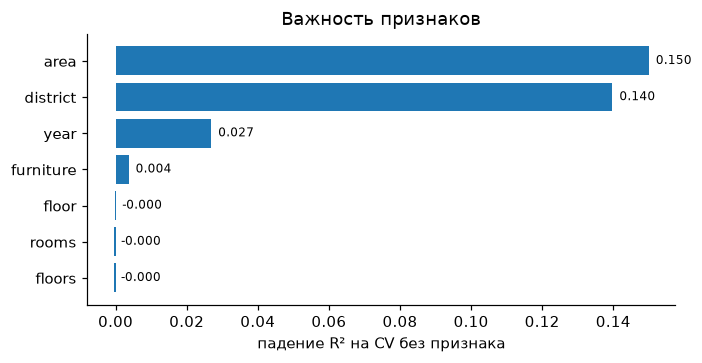

       rooms  area
rooms   1.00  0.91
area    0.91  1.00


In [14]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
s = imp.sort_values()
ax.barh(s.index, s.values)
for i, v in enumerate(s.values):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlabel("падение R² на CV без признака")
ax.set_title("Важность признаков")
plt.tight_layout()
plt.show()
print(X_train[["rooms", "area"]].corr().round(2))

**Вывод.**
- Сильнее всего на цену влияют площадь и район. Без площади R² падает на 0,150, без района на 0,140. Год постройки даёт ещё 0,027, остальные признаки почти ничего.
- У `rooms` в шаге 5 есть вес, но без него качество не меняется. Корреляция комнат и площади 0,91, и площадь уже несёт ту же информацию.
- У года вес +14 562, примерно как у районов, но важность у него в пять раз меньше, чем у района.
- Большой вес не значит, что признак важен. Вес зависит от кодирования и от связи с другими признаками. Удаление признака проверяет важность напрямую.